<a href="https://colab.research.google.com/github/johnriskquant/math-for-ml-data-science-notes/blob/main/prob-stats/week-3-sampling-and-point-estimation/Central_Limit_Theorem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Lets explore applications of CLT when working with different distributions of data. We'll also consider scenarios where the theorem does not hold

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm

**Gaussian Population**
Lets begin with a population that follows a gaussian distribution. We will generate data for this population by using the [np.random.normal](https://numpy.org/doc/stable/reference/random/generated/numpy.random.normal.html) function.

In [ ]:
mu = 10
sigma = 5
gaussian_population = np.random.normal(mu, sigma, 100_000)

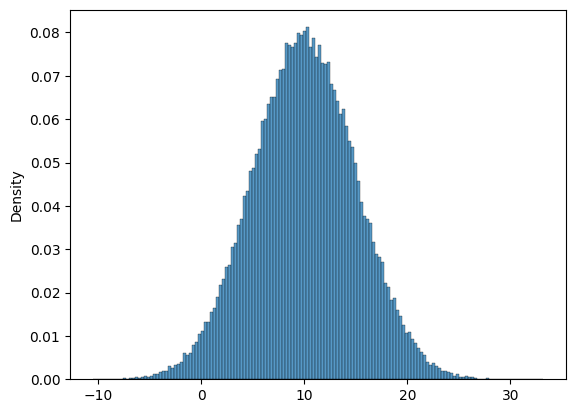

In [ ]:
sns.histplot(gaussian_population, stat='density')
plt.show()

**Sampling from the population**

Lets create a function that samples from our synthetic population data, assuming we dont have access to the population data.


In [ ]:
def sample_means(data:np.ndarray, sample_size:int)->np.ndarray:

  means = [
      np.mean(np.random.choice(data, size=sample_size)) for _ in range(10_000)
      ]
  return np.array(means)

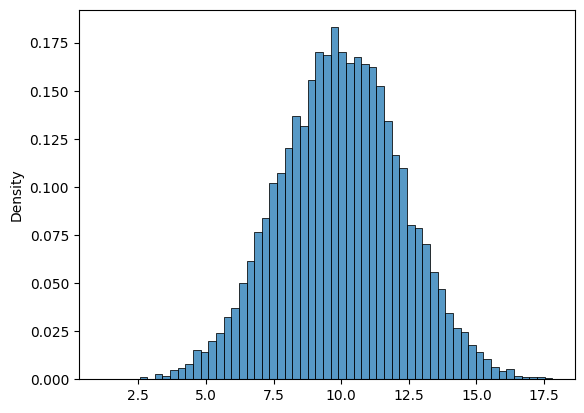

In [ ]:
gauss_sample_means = sample_means(gaussian_population, 5)
sns.histplot(gauss_sample_means, stat='density')
plt.show()

The distribution of the sample means looks pretty Gaussian. However this is not good enough to determine if the theorem holds, after all you used a very small `sample_size` in this example. There are various ways to check if the sample means do follow a Gaussian distribution.

The first one is to compute the theoretical $\mu$ and $\sigma$ of the sample means which will be denoted with the symbols $\mu_{\bar{X}}$ and $\sigma_{\bar{X}}$ respectively. These values can be computed as follows:

- $\mu_{\bar{X}} = \mu$


- $\sigma_{\bar{X}} = \frac{\sigma}{\sqrt{n}}$

**Note: In this case $n$ is the size of the sample.**

And then use these values to plot a Gaussian curve with parameters $\mu_{\bar{X}}$ and $\sigma_{\bar{X}}$. If the theorem holds then the resulting distribution of the sample means should resemble this Gaussian curve. Run the next cell to include this into the plot:

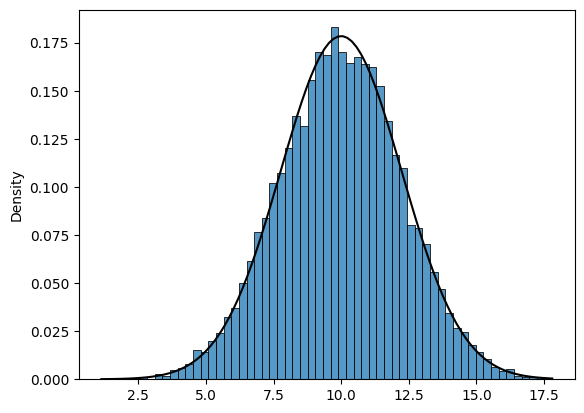

In [ ]:
# Compute estimated mu
mu_sample_means = mu

# Compute estimated sigma
# 5 is being used because you used a sample size of 5
sigma_sample_means = sigma / np.sqrt(5)

# Define the x-range for the Gaussian curve (this is just for plotting purposes)
x_range = np.linspace(min(gauss_sample_means), max(gauss_sample_means), 100)

# Plot everything together
sns.histplot(gauss_sample_means, stat="density")
plt.plot(
    x_range,
    norm.pdf(x_range, loc=mu_sample_means, scale=sigma_sample_means),
    color="black",
)
plt.show()

They look pretty similar. However you can go one step further and plot a smooth function that attempts to estimate the probability density function of the sample means through a method known as `kernel density estimation`. If this smooth function resembles the Gaussian function then you know that the distribution of the sample means is very similar to a Gaussian:

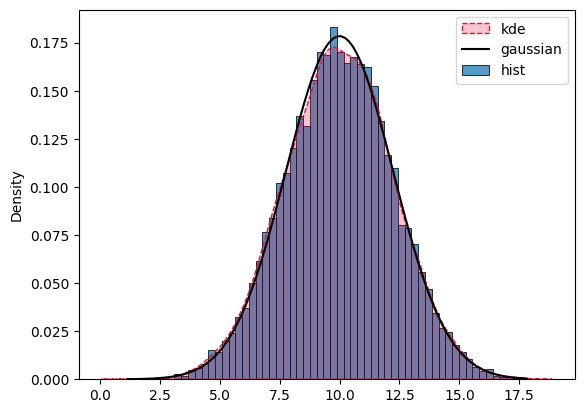

In [ ]:
# Histogram of sample means (blue)
sns.histplot(gauss_sample_means, stat="density", label="hist")

# Estimated PDF of sample means (red)
sns.kdeplot(
    data=gauss_sample_means,
    color="crimson",
    label="kde",
    linestyle="dashed",
    fill=True,
)

# Gaussian curve with estimated mu and sigma (black)
plt.plot(
    x_range,
    norm.pdf(x_range, loc=mu_sample_means, scale=sigma_sample_means),
    color="black",
    label="gaussian",
)

plt.legend()
plt.show()

Both curves look almost identical!

Another way of checking for normality is to perform a QQ plot of the sample means. The points in this plot should resemble a straight line if the distribution of the data is Gaussian:

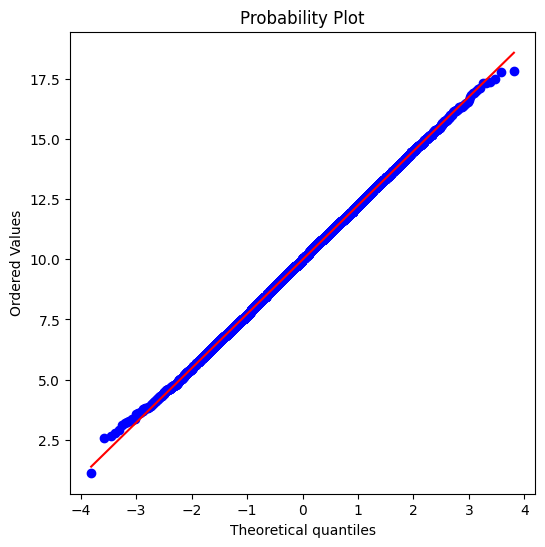

In [ ]:
# Create the QQ plot
fig, ax = plt.subplots(figsize=(6, 6))
res = stats.probplot(gauss_sample_means, plot=ax, fit=True)
plt.show()

**Cauchy Distributions**

The Cauchy distribution is not as well-known as the other ones seen throughout this lab. It has heavy tails, which means that the probability of observing extreme values is higher than in other distributions with similar spread. It also does not have a well-defined mean or variance, which makes it less suitable for many statistical applications.

As a result of the properties of this distribution, the central limit theorem does not hold. Run the next cell to generate a population of 1000 points that distribute Cauchy:

In [ ]:
cauchy_population = np.random.standard_cauchy(1000)

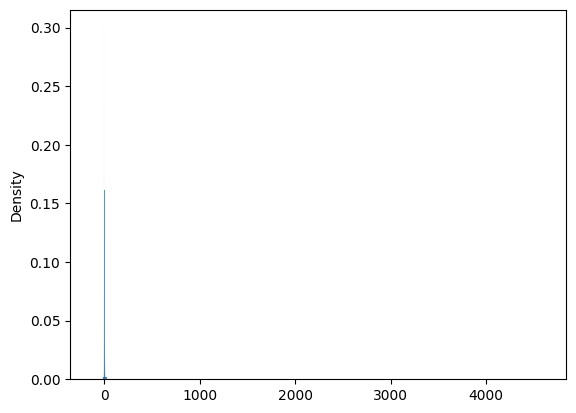

In [ ]:
sns.histplot(cauchy_population, stat="density", label="hist")
plt.show()

In [ ]:
cauchy_sample_means = sample_means(cauchy_population, sample_size=30)

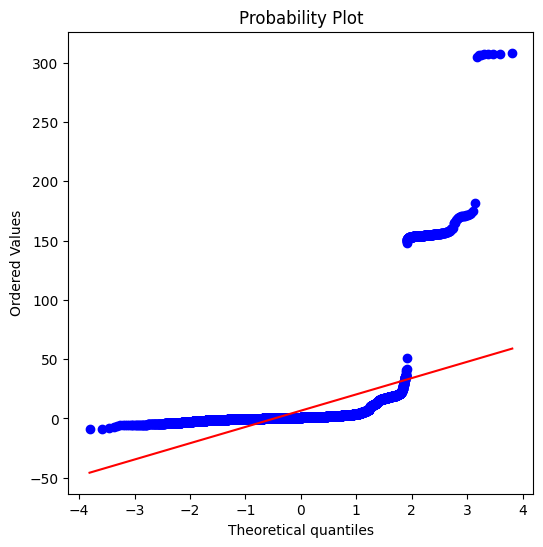

In [ ]:
# Create the QQ plot
fig, ax = plt.subplots(figsize=(6, 6))
res = stats.probplot(cauchy_sample_means, plot=ax, fit=True)
plt.show()

As you can see, this is very different from a straight line which let's you know that the sample means do not distribute normally. But what if you used a much bigger `sample_size`?

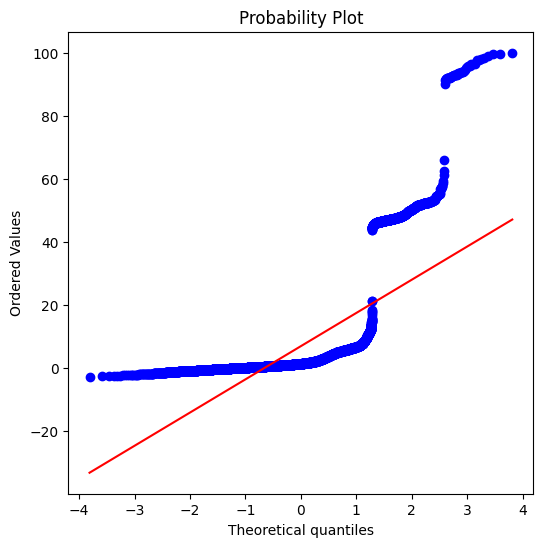

In [ ]:
cauchy_sample_means = sample_means(cauchy_population, sample_size=100)

# Create the QQ plot
fig, ax = plt.subplots(figsize=(6, 6))
res = stats.probplot(cauchy_sample_means, plot=ax, fit=True)
plt.show()

Even when using a `sample_size` of 100, which might be unrealistic in real-life scenarios you still don't achieve normality for the sample means. This is important because it is a fact that the central limit theorem does not hold for all distributions and that is a limitation to consider when applying it.